# Oasis Infobyte Data Analytics Internship (Level 2)
## Task 1: Predicting House Prices with Linear Regression
**Author:** Yasmeen Akhter  
**GitHub Repository:** OIBSIP  
**Tech Stack:** Python, Pandas, Scikit-Learn, Matplotlib, Seaborn, Jupyter Notebook  

### Project Objective
Build and evaluate a linear regression model that predicts house prices based on various features. Develop end-to-end skills from data cleaning and exploratory data analysis (EDA) through to model training, evaluation, and coefficient interpretation.

### Step 1: Load Dataset and Perform EDA
We load the California Housing dataset from scikit-learn, check for missing values, view descriptive statistics, and examine the distribution of the target variable (House Price).

c:\Users\premier computer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\datasets\_base.py:1521: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976036
  warnings.warn(f"Retry downloading from url: {remote.url}")


--- DATASET SHAPE ---
(20640, 9)

--- MISSING VALUES ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

--- DESCRIPTIVE STATISTICS ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


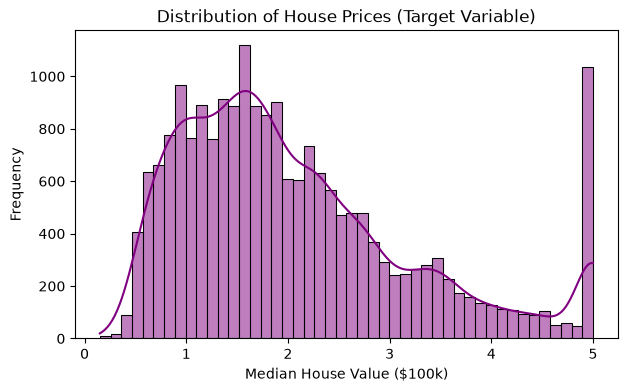

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

# Dataset load karein
california = fetch_california_housing(as_frame=True)
df = california.frame

print("--- DATASET SHAPE ---")
print(df.shape)

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\n--- DESCRIPTIVE STATISTICS ---")
display(df.describe())

# Target variable (Price) distribution plot
plt.figure(figsize=(7, 4))
sns.histplot(df['MedHouseVal'], kde=True, color='purple')
plt.title('Distribution of House Prices (Target Variable)')
plt.xlabel('Median House Value ($100k)')
plt.ylabel('Frequency')
plt.show()

### Step 2: Feature Selection Discussion
In this dataset, features like **MedInc** (Median Income), **AveRooms** (Average Rooms per household), **HouseAge** (House Age), and geographic coordinates (**Latitude**, **Longitude**) strongly influence house prices. Higher income and more rooms generally drive prices up, while older houses or locations far from economic hubs may vary in value.

### Step 3: Correlation Heatmap
We compute the correlation matrix to identify which features have the strongest linear relationship with the house price (`MedHouseVal`).

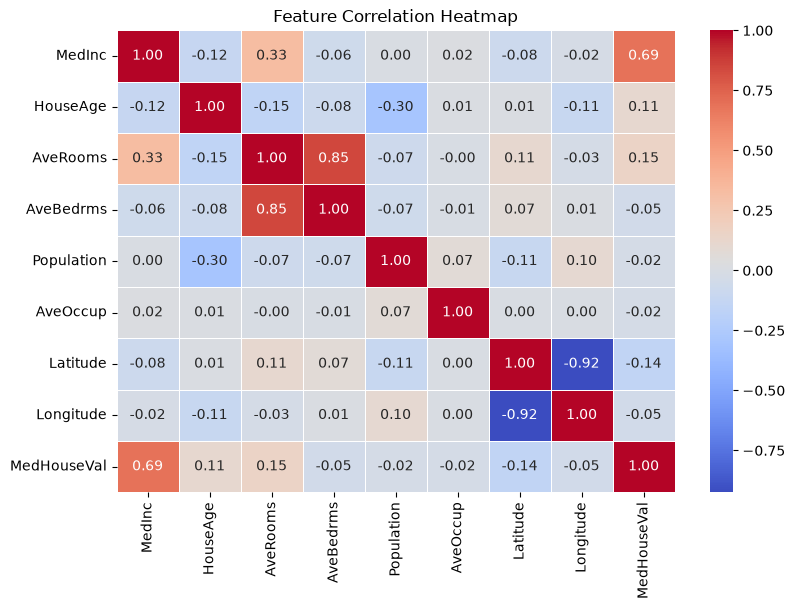

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


In [8]:
plt.figure(figsize=(9, 6))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

# Price ke sath correlation sort kar ke dekhna
print(correlation_matrix['MedHouseVal'].sort_values(ascending=False))

### Step 4: Train/Test Split and Model Training
We split the data into 80% training and 20% testing sets, then train a **Linear Regression** model using scikit-learn.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Features (X) aur Target (y) alag karein
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression model train karein
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


### Step 5: Model Evaluation
We evaluate our model on the test set using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R² (Coefficient of Determination) score.

In [10]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = lr_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R² Score: 0.5758


### Step 6: Visualisations (Actual vs Predicted & Residuals)
- **Scatter Plot:** Compares actual house prices against predicted prices (closer to the diagonal line means better predictions).
- **Residual Plot:** Checks if residuals (errors) are randomly distributed around zero without systematic patterns.

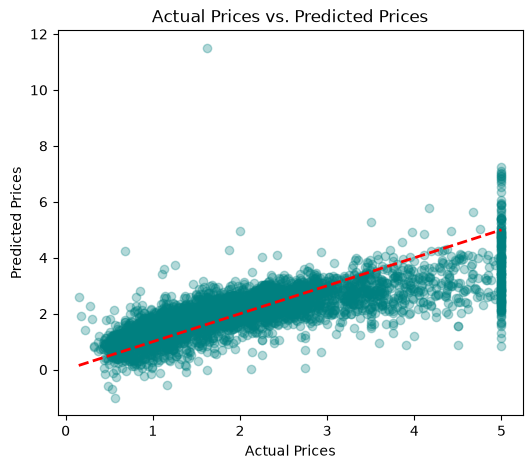

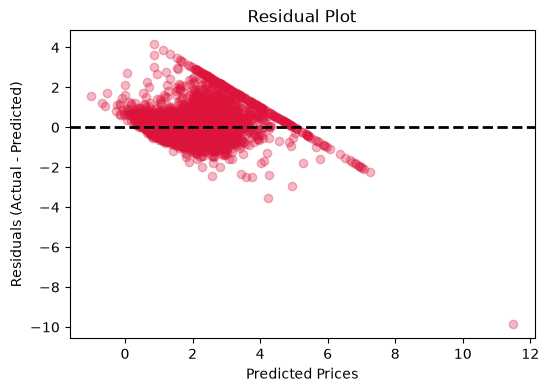

In [11]:
# 1. Actual vs Predicted Scatter Plot
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.3, color='teal')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.title('Actual Prices vs. Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.show()

# 2. Residual Plot
residuals = y_test - y_pred
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals, alpha=0.3, color='crimson')
plt.axhline(y=0, color='black', linestyle='--', lw=2)
plt.title('Residual Plot')
plt.xlabel('Predicted Prices')
plt.ylabel('Residuals (Actual - Predicted)')
plt.show()

### Step 7: Coefficient Analysis
We examine the regression coefficients to see which features have the highest positive or negative impact on house prices.

,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
1,HouseAge,0.009724
4,Population,-0.000002
5,AveOccup,-0.003526
2,AveRooms,-0.123323
6,Latitude,-0.419792
7,Longitude,-0.433708


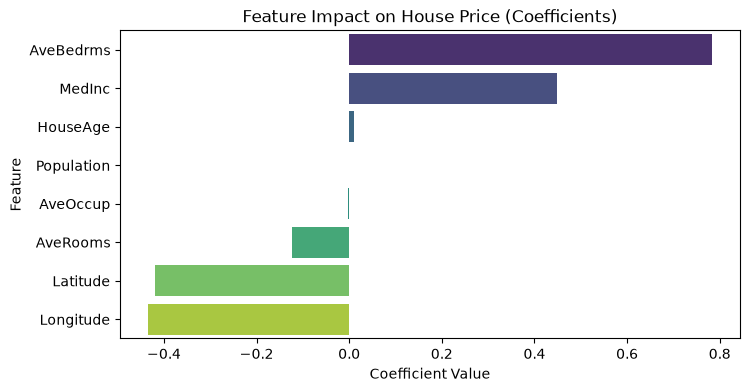

In [12]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
}).sort_values(by='Coefficient', ascending=False)

display(coefficients)

# Bar chart of coefficients
plt.figure(figsize=(8, 4))
sns.barplot(x='Coefficient', y='Feature', data=coefficients, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Impact on House Price (Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

### Step 8: (Bonus) Comparison with Ridge Regression
We train a Ridge regularised regression model to prevent overfitting and compare its R² score with standard Linear Regression.

In [13]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

ridge_r2 = r2_score(y_test, y_pred_ridge)
print(f"Standard Linear Regression R²: {r2:.4f}")
print(f"Ridge Regression R²: {ridge_r2:.4f}")

Standard Linear Regression R²: 0.5758
Ridge Regression R²: 0.5759
